# Agente para Flappy Bird con Q-Learning
**UPAO – IA Principios y Técnicas.** Notebook de apoyo al informe (secciones III, IV y V).
Ejecutar las celdas en orden (Entorno de ejecución → Ejecutar todo). Tiempo total aproximado: 10–15 min en CPU.

## 0. Preparación del entorno

In [ ]:
# Celda 0.1 – Librerías y semillas (RNF-03 Reproducibilidad, RNF-04 Portabilidad)
import random, pickle, time, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
try:
    from IPython.display import display, Image
except ImportError:
    display = print

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("NumPy", np.__version__, "| Pandas", pd.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.1.3 | Pandas 2.2.3 | Matplotlib 3.10.0


In [ ]:
# Celda 0.2 – Hiperparámetros (sección 4.2) y parámetros del experimento
CONFIG = dict(
    alpha=0.1, gamma=0.95,                      # tasa de aprendizaje y factor de descuento
    eps0=1.0, eps_min=0.01, decay=0.995,        # política ε-greedy con decaimiento por episodio
    bins=(15, 20, 12),                          # discretización (dx, dy, vel)
    q_init=2.0,                                 # inicialización optimista de la Q-Table
    dy_range=128.0,                             # px que cubre el rango [-1, 1] de dy
    n_train=10_000, n_test=200,                 # episodios de entrenamiento / prueba
    eval_every=500, eval_episodes=50,           # validación periódica (greedy)
    max_steps_train=5_000, max_steps_val=5_000, max_steps_test=10_000,
    seed=SEED,
)
VAL_SEED0, TEST_SEED0, CROSS_SEED0 = 20_000, 10_000, 50_000   # bloques de semillas independientes
pd.Series(CONFIG, name="valor").to_frame()

,valor
alpha,0.1
gamma,0.95
eps0,1.0
eps_min,0.01
decay,0.995
bins,"(15, 20, 12)"
q_init,2.0
dy_range,128.0
n_train,10000
n_test,200


## Módulo 1 – Entorno de simulación (FlappyBirdEnv)

In [ ]:
# Celda 1 – Módulo 1: FlappyBirdEnv (RF-01). Simulación headless de la física de Flappy Bird.
class FlappyBirdEnv:
    W, H, GROUND = 288, 512, 400            # pantalla y altura del suelo (px)
    BIRD_X, BIRD_R = 60, 12                 # posición horizontal fija y radio del pájaro
    GRAVITY, FLAP_V, V_MAX = 1.0, -9.0, 10.0
    PIPE_W, PIPE_SPEED, GAP, SPACING = 52, 4, 100, 180

    def __init__(self, seed=None, max_steps=5000):
        self.rng = random.Random(seed)
        self.max_steps = max_steps

    def _new_pipe(self, x):                 # [x, centro de la abertura, ya_cruzado]
        lo, hi = self.GAP // 2 + 40, self.GROUND - self.GAP // 2 - 40
        return [x, self.rng.randint(lo, hi), False]

    def reset(self, seed=None):
        if seed is not None:
            self.rng = random.Random(seed)
        self.y, self.vel, self.score, self.steps = 256.0, 0.0, 0, 0
        self.pipes = [self._new_pipe(self.W + 40)]
        while len(self.pipes) < 4:
            self.pipes.append(self._new_pipe(self.pipes[-1][0] + self.SPACING))
        return self._obs()

    def _next_pipe(self):
        for p in self.pipes:
            if p[0] + self.PIPE_W >= self.BIRD_X - self.BIRD_R:
                return p
        return self.pipes[-1]

    def _obs(self):
        """Observación continua: (dx, dy, vel). dy>0: pájaro por encima del centro; vel>0: ascenso."""
        p = self._next_pipe()
        return (max(0.0, p[0] - self.BIRD_X), p[1] - self.y, -self.vel)

    def step(self, action):                 # action: 0 = no hacer nada, 1 = saltar
        self.steps += 1
        self.vel = self.FLAP_V if action == 1 else min(self.vel + self.GRAVITY, self.V_MAX)
        self.y += self.vel
        for p in self.pipes:
            p[0] -= self.PIPE_SPEED
        if self.pipes[0][0] + self.PIPE_W < 0:
            self.pipes.pop(0)
            self.pipes.append(self._new_pipe(self.pipes[-1][0] + self.SPACING))
        r, crashed = self.BIRD_R, False
        if self.y - r < 0 or self.y + r > self.GROUND:
            crashed = True
        else:
            for p in self.pipes:
                if p[0] < self.BIRD_X + r and p[0] + self.PIPE_W > self.BIRD_X - r:
                    if self.y - r < p[1] - self.GAP / 2 or self.y + r > p[1] + self.GAP / 2:
                        crashed = True
                    break
        reward = -1.0 if crashed else 0.1                      # RF-04: -1 colisión, +0.1 por sobrevivir
        if not crashed:
            for p in self.pipes:
                if not p[2] and p[0] + self.PIPE_W < self.BIRD_X - r:
                    p[2] = True; self.score += 1; reward += 1.0  # +1 por cruzar un par de tubos
        done = crashed or self.steps >= self.max_steps         # límite de pasos = episodio superado
        return self._obs(), reward, done, {"score": self.score, "crashed": crashed}

    def snapshot(self):
        return dict(y=self.y, pipes=[list(p) for p in self.pipes], score=self.score)

# Prueba rápida del entorno con una política aleatoria
env = FlappyBirdEnv(seed=0)
obs = env.reset()
print("Observación inicial (dx, dy, vel):", tuple(round(v, 1) for v in obs))
for t in range(1000):
    obs, r, done, info = env.step(random.randint(0, 1))
    if done: break
print(f"Episodio aleatorio terminó en {t+1} pasos | score={info['score']} | choque={info['crashed']}")

Observación inicial (dx, dy, vel): (268, 50.0, -0.0)
Episodio aleatorio terminó en 36 pasos | score=0 | choque=True


## III. Data-set, pre-procesamiento y normalización

In [ ]:
# Celda 2 – 3.1 Elaboración del Data-Set: experiencias (s, a, r, s') generadas por una política exploratoria
def collect_random_dataset(n_episodes=300, seed=0):
    env, rows = FlappyBirdEnv(seed=seed, max_steps=500), []
    rng = random.Random(seed)
    for ep in range(n_episodes):
        obs = env.reset()
        while True:
            a = 1 if rng.random() < 0.1 else 0          # exploración sesgada: salta con p = 0.1
            nxt, r, done, info = env.step(a)
            rows.append(dict(episodio=ep, dx=obs[0], dy=obs[1], vel=obs[2], accion=a, recompensa=r,
                             dx_sig=nxt[0], dy_sig=nxt[1], vel_sig=nxt[2], terminal=info["crashed"]))
            obs = nxt
            if done: break
    return pd.DataFrame(rows)

df_exp = collect_random_dataset()
print(f"Experiencias generadas: {len(df_exp):,} (300 episodios)")
display(df_exp.head(8))
display(df_exp[["dx", "dy", "vel", "recompensa"]].describe().round(2))

Experiencias generadas: 16,396 (300 episodios)


,episodio,dx,dy,vel,accion,recompensa,dx_sig,dy_sig,vel_sig,terminal
0,0,268.0,50.0,-0.0,0,0.1,264.0,49.0,-1.0,False
1,0,264.0,49.0,-1.0,0,0.1,260.0,47.0,-2.0,False
2,0,260.0,47.0,-2.0,0,0.1,256.0,44.0,-3.0,False
3,0,256.0,44.0,-3.0,0,0.1,252.0,40.0,-4.0,False
4,0,252.0,40.0,-4.0,0,0.1,248.0,35.0,-5.0,False
5,0,248.0,35.0,-5.0,0,0.1,244.0,29.0,-6.0,False
6,0,244.0,29.0,-6.0,0,0.1,240.0,22.0,-7.0,False
7,0,240.0,22.0,-7.0,0,0.1,236.0,14.0,-8.0,False


,dx,dy,vel,recompensa
count,16396.00,16396.00,16396.00,16396.00
mean,148.22,-9.56,1.24,0.08
std,76.37,107.90,6.17,0.15
min,0.00,-293.00,-10.00,-1.00
25%,84.00,-90.00,-3.00,0.10
50%,152.00,-10.00,2.00,0.10
75%,216.00,63.00,7.00,0.10
max,268.00,295.00,9.00,1.10


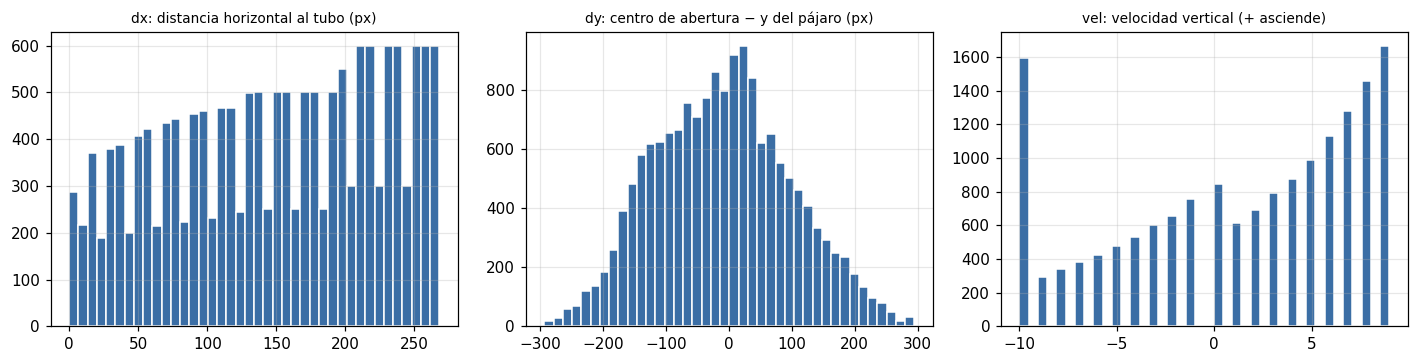

In [ ]:
# Celda 3 – 3.1 Distribución de las variables de estado (medidas crudas)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a_, col, ttl in zip(ax, ["dx", "dy", "vel"],
        ["dx: distancia horizontal al tubo (px)", "dy: centro de abertura − y del pájaro (px)", "vel: velocidad vertical (+ asciende)"]):
    a_.hist(df_exp[col], bins=40, color="#3b6ea5", edgecolor="white"); a_.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.savefig("fig_01_variables_crudas.png", dpi=150); plt.show()

Espacio de estados: (15, 20, 12) → 3,600 estados × 2 acciones = 7,200 valores Q
Estados distintos visitados por la política aleatoria: 2,622 (72.8%)
Rango normalizado → dx:[0.00, 0.93]  dy:[-1.00, 1.00]  vel:[-1.00, 0.90]
Ejemplo: (np.float64(228.0), np.float64(-5.0), np.float64(-10.0)) → estado (11, 9, 0)


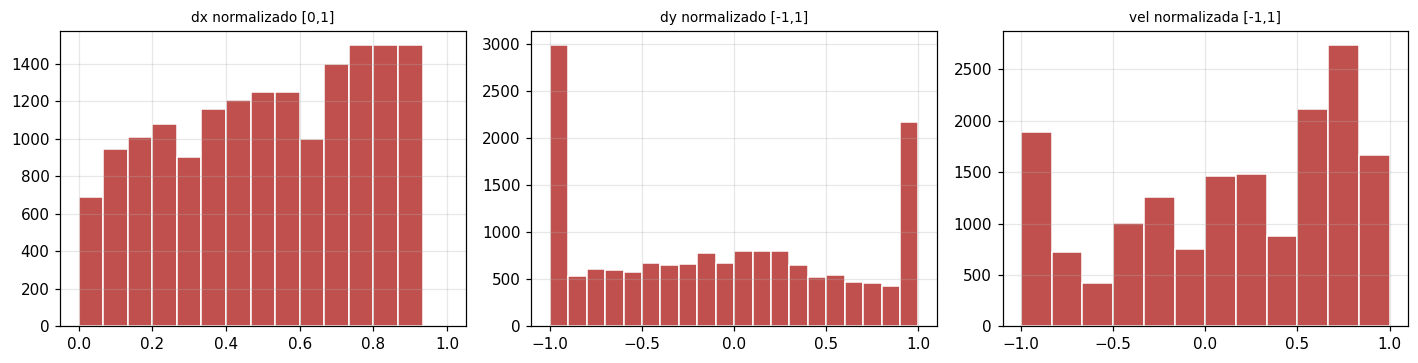

In [ ]:
# Celda 4 – 3.2 Normalización y discretización (Módulo 2: StateDiscretizer)
class StateDiscretizer:
    def __init__(self, cfg):
        self.bins = cfg["bins"]; self.dy_range = cfg["dy_range"]
        self.W = FlappyBirdEnv.W; self.VT = FlappyBirdEnv.V_MAX

    def normalize(self, obs):
        dx, dy, vel = obs
        ndx = min(max(dx / self.W, 0.0), 1.0)                  # [0, 1]  (clipping)
        ndy = min(max(dy / self.dy_range, -1.0), 1.0)          # [-1, 1]
        nv  = min(max(vel / self.VT, -1.0), 1.0)               # [-1, 1]
        return ndx, ndy, nv

    def discretize(self, obs):
        ndx, ndy, nv = self.normalize(obs); b = self.bins
        return (min(int(ndx * b[0]), b[0] - 1),
                min(int((ndy + 1) / 2 * b[1]), b[1] - 1),
                min(int((nv + 1) / 2 * b[2]), b[2] - 1))

disc = StateDiscretizer(CONFIG)
norm = np.array([disc.normalize((r.dx, r.dy, r.vel)) for r in df_exp.itertuples()])
states = [disc.discretize((r.dx, r.dy, r.vel)) for r in df_exp.itertuples()]
n_states = int(np.prod(CONFIG["bins"]))
print(f"Espacio de estados: {CONFIG['bins']} → {n_states:,} estados × 2 acciones = {2*n_states:,} valores Q")
print(f"Estados distintos visitados por la política aleatoria: {len(set(states)):,} ({len(set(states))/n_states:.1%})")
print("Rango normalizado → dx:[%.2f, %.2f]  dy:[%.2f, %.2f]  vel:[%.2f, %.2f]" % (
    norm[:,0].min(), norm[:,0].max(), norm[:,1].min(), norm[:,1].max(), norm[:,2].min(), norm[:,2].max()))
print("Ejemplo:", tuple(round(v,1) for v in (df_exp.dx[10], df_exp.dy[10], df_exp.vel[10])), "→ estado", states[10])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, (a_, ttl, lo) in enumerate(zip(ax, ["dx normalizado [0,1]", "dy normalizado [-1,1]", "vel normalizada [-1,1]"], [0, -1, -1])):
    a_.hist(norm[:, k], bins=CONFIG["bins"][k], range=(lo, 1), color="#c0504d", edgecolor="white"); a_.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.savefig("fig_02_variables_normalizadas.png", dpi=150); plt.show()

In [ ]:
# Celda 5 – 3.3 Organización del Data-Set en RL: entrenamiento / prueba / validación (semillas independientes)
plan = pd.DataFrame([
    ["Entrenamiento (training)", f"{CONFIG['n_train']:,} episodios", "ε-greedy (ε: 1.0 → 0.01)", "Sí (se actualiza la Q-Table)", "flujo de semilla %d" % SEED],
    ["Validación periódica", f"{CONFIG['eval_episodes']} ep. cada {CONFIG['eval_every']} ep.", "greedy (ε = 0)", "No", f"semillas {VAL_SEED0}–{VAL_SEED0+CONFIG['eval_episodes']-1}"],
    ["Prueba (test)", f"{CONFIG['n_test']} episodios", "greedy (ε = 0)", "No (Q-Table congelada)", f"semillas {TEST_SEED0}–{TEST_SEED0+CONFIG['n_test']-1}"],
    ["Validación cruzada adaptada", "5 bloques × 50 episodios", "greedy (ε = 0)", "No", f"semillas {CROSS_SEED0}+ (no vistas)"],
], columns=["Conjunto", "Tamaño", "Política", "Aprende", "Semillas del entorno"])
display(plan)

,Conjunto,Tamaño,Política,Aprende,Semillas del entorno
0,Entrenamiento (training),"10,000 episodios",ε-greedy (ε: 1.0 → 0.01),Sí (se actualiza la Q-Table),flujo de semilla 42
1,Validación periódica,50 ep. cada 500 ep.,greedy (ε = 0),No,semillas 20000–20049
2,Prueba (test),200 episodios,greedy (ε = 0),No (Q-Table congelada),semillas 10000–10199
3,Validación cruzada adaptada,5 bloques × 50 episodios,greedy (ε = 0),No,semillas 50000+ (no vistas)


## IV. Aprendizaje – Agente Q-Learning

In [ ]:
# Celda 6 – 4.2 Módulo 3: QLearningAgent (RF-03, RF-07)
class QLearningAgent:
    def __init__(self, cfg, seed=0):
        self.cfg = cfg
        self.Q = np.full(tuple(cfg["bins"]) + (2,), cfg["q_init"], dtype=np.float64)
        self.visits = np.zeros(tuple(cfg["bins"]), dtype=np.int64)
        self.alpha, self.gamma = cfg["alpha"], cfg["gamma"]
        self.eps0, self.eps_min, self.decay, self.eps = cfg["eps0"], cfg["eps_min"], cfg["decay"], cfg["eps0"]
        self.rng = random.Random(seed)

    def select_action(self, s, greedy=False):           # política ε-greedy
        if not greedy and self.rng.random() < self.eps:
            return self.rng.randint(0, 1)               # exploración
        q = self.Q[s]
        return int(q[1] > q[0])                         # explotación (empate → no saltar)

    def update(self, s, a, r, s_next, terminal):        # Q(s,a) ← Q(s,a) + α[r + γ·max Q(s',a') − Q(s,a)]
        target = r if terminal else r + self.gamma * self.Q[s_next].max()
        self.Q[s + (a,)] += self.alpha * (target - self.Q[s + (a,)])
        self.visits[s] += 1

    def end_episode(self, episode):                     # ε = max(ε_min, ε0·decay^episodio)
        self.eps = max(self.eps_min, self.eps0 * self.decay ** episode)

    def save(self, path="qtable_flappy.pkl"):
        with open(path, "wb") as f: pickle.dump(dict(Q=self.Q, visits=self.visits, cfg=self.cfg), f)

    @classmethod
    def load(cls, path="qtable_flappy.pkl"):
        with open(path, "rb") as f: d = pickle.load(f)
        ag = cls(d["cfg"]); ag.Q, ag.visits, ag.eps = d["Q"], d["visits"], 0.0
        return ag

class RandomAgent:                                       # línea base: acciones aleatorias
    def __init__(self, seed=0): self.rng = random.Random(seed)
    def select_action(self, s, greedy=False): return self.rng.randint(0, 1)

In [ ]:
# Celda 7 – 4.2 Módulo 4/5: bucle de episodio, evaluación y entrenamiento con validación periódica
def run_episode(env, disc, agent, train=False, seed=None):
    s = disc.discretize(env.reset(seed)); total, n = 0.0, 0
    while True:
        a = agent.select_action(s, greedy=not train)
        obs, r, done, info = env.step(a); s2 = disc.discretize(obs)
        if train: agent.update(s, a, r, s2, info["crashed"])
        s, total, n = s2, total + r, n + 1
        if done: return info["score"], total, n, info["crashed"]

def evaluate(agent, disc, seeds, max_steps):
    env = FlappyBirdEnv(max_steps=max_steps)
    res = [run_episode(env, disc, agent, train=False, seed=sd) for sd in seeds]
    return pd.DataFrame(res, columns=["score", "recompensa", "pasos", "choque"])

def train(cfg, n_episodes, eval_every, eval_episodes, verbose=True):
    env = FlappyBirdEnv(seed=cfg["seed"], max_steps=cfg["max_steps_train"])
    disc, agent = StateDiscretizer(cfg), QLearningAgent(cfg, seed=cfg["seed"])
    log, val_log, best_score, best_Q = [], [], -1, agent.Q.copy()
    val_seeds = range(VAL_SEED0, VAL_SEED0 + eval_episodes); t0 = time.time()
    for ep in range(1, n_episodes + 1):
        score, ret, n, _ = run_episode(env, disc, agent, train=True)
        agent.end_episode(ep)
        seen = agent.visits > 0
        log.append(dict(episodio=ep, score=score, recompensa=ret, pasos=n, epsilon=agent.eps,
                        q_medio=float(agent.Q[seen].mean())))
        if ep % eval_every == 0:                                  # validación greedy (Q congelada)
            v = evaluate(agent, disc, val_seeds, cfg["max_steps_val"])
            val_log.append(dict(episodio=ep, media=v.score.mean(), std=v.score.std(), max=v.score.max()))
            if v.score.mean() > best_score:                       # checkpoint de la mejor Q-Table
                best_score, best_Q = v.score.mean(), agent.Q.copy()
            if verbose and ep % (eval_every * 2) == 0:
                print(f"ep {ep:>6} | ε={agent.eps:.3f} | score train(últ.500)={np.mean([l['score'] for l in log[-500:]]):6.1f}"
                      f" | validación={v.score.mean():6.1f} (máx {v.score.max()}) | {time.time()-t0:5.0f}s")
    final_Q = agent.Q.copy()
    agent.Q = best_Q                                              # el agente final usa el mejor checkpoint
    return agent, pd.DataFrame(log), pd.DataFrame(val_log), final_Q

## V. Comprobación – entrenamiento y prueba

In [ ]:
# Celda 8 – Entrenamiento (Data-Set de Entrenamiento). Tarda ~3–6 min.
agent, log, val_log, final_Q = train(CONFIG, CONFIG["n_train"], CONFIG["eval_every"], CONFIG["eval_episodes"])
best_row = val_log.loc[val_log["media"].idxmax()]
print(f"\nMejor checkpoint: episodio {int(best_row.episodio)} con validación media = {best_row['media']:.1f}")
agent.save("qtable_flappy.pkl"); np.save("qtable_flappy.npy", agent.Q)       # RF-07 persistencia

ep   1000 | ε=0.010 | score train(últ.500)=   2.0 | validación=  11.3 (máx 51) |     1s
ep   2000 | ε=0.010 | score train(últ.500)=   5.1 | validación=  21.0 (máx 73) |     4s
ep   3000 | ε=0.010 | score train(últ.500)=   4.8 | validación=  21.4 (máx 84) |     6s
ep   4000 | ε=0.010 | score train(últ.500)=   7.1 | validación=  39.3 (máx 110) |    10s
ep   5000 | ε=0.010 | score train(últ.500)=   8.0 | validación=  43.6 (máx 110) |    13s
ep   6000 | ε=0.010 | score train(últ.500)=   7.5 | validación=  45.8 (máx 110) |    17s
ep   7000 | ε=0.010 | score train(últ.500)=   7.5 | validación=  50.5 (máx 110) |    21s
ep   8000 | ε=0.010 | score train(últ.500)=   7.3 | validación=  44.9 (máx 110) |    25s
ep   9000 | ε=0.010 | score train(últ.500)=   7.2 | validación=  59.5 (máx 110) |    29s
ep  10000 | ε=0.010 | score train(últ.500)=   7.1 | validación=  58.6 (máx 110) |    33s

Mejor checkpoint: episodio 9500 con validación media = 64.9


,score_medio,score_max,pasos_medios,recompensa_media,epsilon_fin,q_medio
bloque,,,,,,
1000,1.01,17,105.22,10.43,0.01,1.97
2000,5.04,33,294.88,33.43,0.01,1.96
3000,5.09,49,297.25,33.72,0.01,1.95
4000,6.80,41,374.54,43.16,0.01,1.94
5000,7.78,63,418.92,48.58,0.01,1.93
6000,7.59,67,411.33,47.63,0.01,1.92
7000,7.52,50,408.01,47.22,0.01,1.91
8000,7.84,53,422.18,48.96,0.01,1.90
9000,7.36,57,400.50,46.31,0.01,1.89


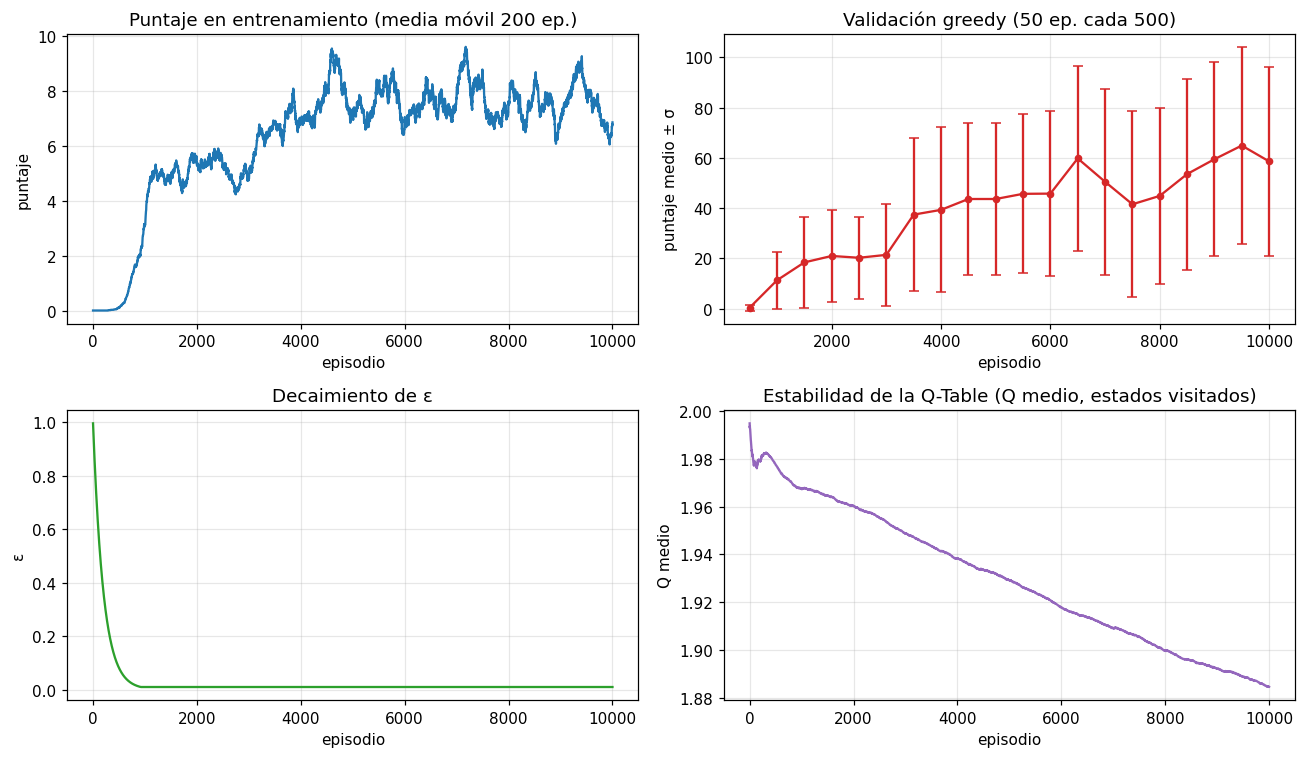

In [ ]:
# Celda 9 – Resultados de entrenamiento: tabla por bloques de 1000 episodios + curvas de aprendizaje (RF-06)
log["bloque"] = (log.episodio - 1) // 1000 * 1000 + 1000
tabla_train = log.groupby("bloque").agg(score_medio=("score", "mean"), score_max=("score", "max"),
        pasos_medios=("pasos", "mean"), recompensa_media=("recompensa", "mean"), epsilon_fin=("epsilon", "last"),
        q_medio=("q_medio", "last")).round(2)
display(tabla_train)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
w = 200
ax[0,0].plot(log.episodio, log.score.rolling(w, min_periods=1).mean(), color="#1f77b4")
ax[0,0].set(title=f"Puntaje en entrenamiento (media móvil {w} ep.)", xlabel="episodio", ylabel="puntaje")
ax[0,1].errorbar(val_log.episodio, val_log["media"], yerr=val_log["std"], fmt="o-", color="#d62728", capsize=3, ms=4)
ax[0,1].set(title=f"Validación greedy ({CONFIG['eval_episodes']} ep. cada {CONFIG['eval_every']})", xlabel="episodio", ylabel="puntaje medio ± σ")
ax[1,0].plot(log.episodio, log.epsilon, color="#2ca02c"); ax[1,0].set(title="Decaimiento de ε", xlabel="episodio", ylabel="ε")
ax[1,1].plot(log.episodio, log.q_medio, color="#9467bd"); ax[1,1].set(title="Estabilidad de la Q-Table (Q medio, estados visitados)", xlabel="episodio", ylabel="Q medio")
plt.tight_layout(); plt.savefig("fig_03_curvas_aprendizaje.png", dpi=150); plt.show()

,media,mediana,maximo,minimo,desv_std,pasos_medios,tasa_supervivencia
Q-Learning (mejor checkpoint),98.69,84.0,221.0,1.0,69.48,4504.90,0.12
Q-Learning (Q-Table final),71.74,54.0,221.0,1.0,60.27,3292.88,0.06
Agente aleatorio (línea base),0.00,0.0,0.0,0.0,0.00,32.24,0.00


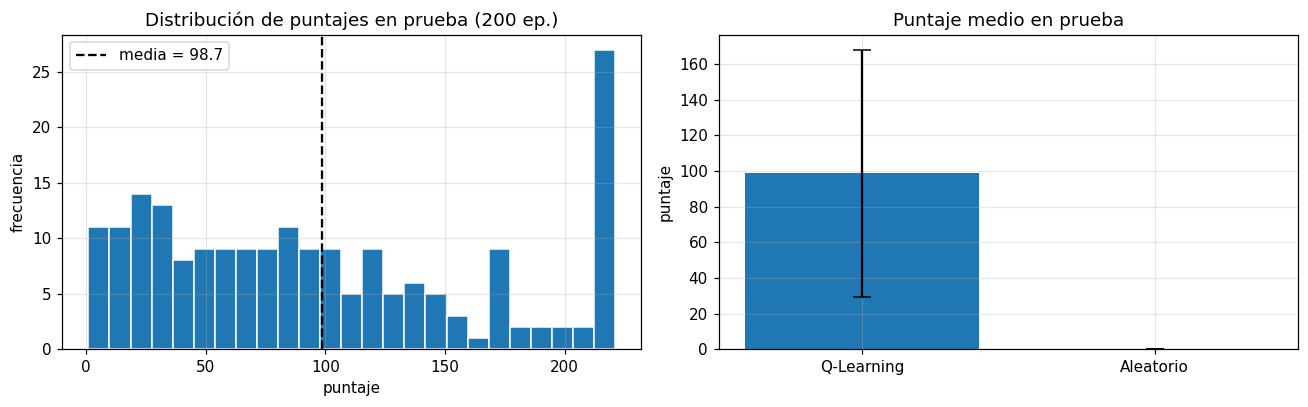

In [ ]:
# Celda 10 – Prueba (Data-Set de Test): política greedy ε = 0, Q-Table congelada, semillas no usadas en entrenamiento
disc = StateDiscretizer(CONFIG)
test = evaluate(agent, disc, range(TEST_SEED0, TEST_SEED0 + CONFIG["n_test"]), CONFIG["max_steps_test"])
base = evaluate(RandomAgent(CONFIG["seed"]), disc, range(TEST_SEED0, TEST_SEED0 + CONFIG["n_test"]), CONFIG["max_steps_test"])
final_agent = QLearningAgent(CONFIG); final_agent.Q = final_Q
fin  = evaluate(final_agent, disc, range(TEST_SEED0, TEST_SEED0 + CONFIG["n_test"]), CONFIG["max_steps_test"])

def resumen(df):
    return dict(media=df.score.mean(), mediana=df.score.median(), maximo=df.score.max(), minimo=df.score.min(),
                desv_std=df.score.std(), pasos_medios=df.pasos.mean(), tasa_supervivencia=1 - df.choque.mean())
tabla_test = pd.DataFrame({"Q-Learning (mejor checkpoint)": resumen(test),
                           "Q-Learning (Q-Table final)": resumen(fin),
                           "Agente aleatorio (línea base)": resumen(base)}).T.round(2)
display(tabla_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(test.score, bins=25, color="#1f77b4", edgecolor="white"); ax[0].axvline(test.score.mean(), color="k", ls="--", label=f"media = {test.score.mean():.1f}")
ax[0].set(title=f"Distribución de puntajes en prueba ({CONFIG['n_test']} ep.)", xlabel="puntaje", ylabel="frecuencia"); ax[0].legend()
ax[1].bar(["Q-Learning", "Aleatorio"], [test.score.mean(), base.score.mean()], yerr=[test.score.std(), base.score.std()], color=["#1f77b4", "#999"], capsize=6)
ax[1].set(title="Puntaje medio en prueba", ylabel="puntaje")
plt.tight_layout(); plt.savefig("fig_04_prueba.png", dpi=150); plt.show()

In [ ]:
# Celda 11 – Validación cruzada adaptada: 5 bloques de semillas nunca vistas (generalización)
bloques = []
for b in range(5):
    sd0 = CROSS_SEED0 + b * 100
    r = evaluate(agent, disc, range(sd0, sd0 + 50), CONFIG["max_steps_test"])
    bloques.append(dict(bloque=b + 1, semillas=f"{sd0}–{sd0+49}", media=r.score.mean(), std=r.score.std(),
                        maximo=r.score.max(), supervivencia=1 - r.choque.mean()))
cv = pd.DataFrame(bloques).round(2); display(cv)
print(f"Media entre bloques: {cv.media.mean():.1f} ± {cv.media.std():.1f}  (coef. de variación = {cv.media.std()/cv.media.mean():.1%})")

,bloque,semillas,media,std,maximo,supervivencia
0,1,50000–50049,93.86,72.12,221,0.12
1,2,50100–50149,106.08,73.45,221,0.16
2,3,50200–50249,87.40,72.19,221,0.12
3,4,50300–50349,94.20,72.53,221,0.08
4,5,50400–50449,85.56,70.01,221,0.10


Media entre bloques: 93.4 ± 8.0  (coef. de variación = 8.6%)


Base                       test_media=  20.8
α = 0.05                   test_media=  86.2
α = 0.3                    test_media=  84.7
γ = 0.90                   test_media=   0.1
γ = 0.99                   test_media=   0.4
decay = 0.998              test_media=  40.5
bins pequeños (10,15,8)    test_media=  66.5
bins grandes (20,25,16)    test_media=  18.1
dy_range = 256             test_media=  24.5
Q inicial = 0              test_media=   0.5


,configuración,val_mejor,test_media,test_max,supervivencia
0,α = 0.05,88.85,86.22,110,0.60
1,α = 0.3,85.15,84.68,110,0.60
2,"bins pequeños (10,15,8)",74.15,66.50,110,0.28
3,decay = 0.998,37.40,40.50,110,0.08
4,dy_range = 256,28.45,24.48,93,0.00
5,Base,22.90,20.76,63,0.00
6,"bins grandes (20,25,16)",19.40,18.12,71,0.00
7,Q inicial = 0,0.45,0.48,3,0.00
8,γ = 0.99,0.30,0.38,5,0.00
9,γ = 0.90,0.25,0.08,2,0.00


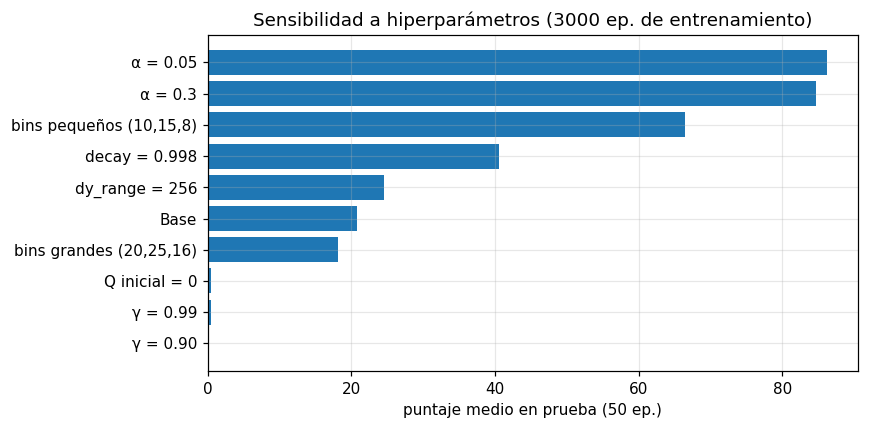

In [ ]:
# Celda 12 – Análisis de sensibilidad de hiperparámetros (entrenamientos cortos de 3000 episodios). Tarda ~5–8 min.
variantes = {
    "Base":              {},
    "α = 0.05":          dict(alpha=0.05),
    "α = 0.3":           dict(alpha=0.3),
    "γ = 0.90":          dict(gamma=0.90),
    "γ = 0.99":          dict(gamma=0.99),
    "decay = 0.998":     dict(decay=0.998),
    "bins pequeños (10,15,8)":  dict(bins=(10, 15, 8)),
    "bins grandes (20,25,16)":  dict(bins=(20, 25, 16)),
    "dy_range = 256":    dict(dy_range=256.0),
    "Q inicial = 0":     dict(q_init=0.0),
}
filas = []
for nombre, ov in variantes.items():
    cfg = {**CONFIG, **ov}
    ag, _, vlog, _ = train(cfg, 3000, 500, 20, verbose=False)
    t = evaluate(ag, StateDiscretizer(cfg), range(TEST_SEED0, TEST_SEED0 + 50), 5000)
    filas.append(dict(configuración=nombre, val_mejor=vlog["media"].max(), test_media=t.score.mean(), test_max=t.score.max(),
                      supervivencia=1 - t.choque.mean()))
    print(f"{nombre:<26} test_media={t.score.mean():6.1f}")
sens = pd.DataFrame(filas).round(2).sort_values("test_media", ascending=False).reset_index(drop=True)
display(sens)
plt.figure(figsize=(8, 4)); plt.barh(sens["configuración"][::-1], sens["test_media"][::-1], color="#1f77b4")
plt.xlabel("puntaje medio en prueba (50 ep.)"); plt.title("Sensibilidad a hiperparámetros (3000 ep. de entrenamiento)")
plt.tight_layout(); plt.savefig("fig_05_sensibilidad.png", dpi=150); plt.show()

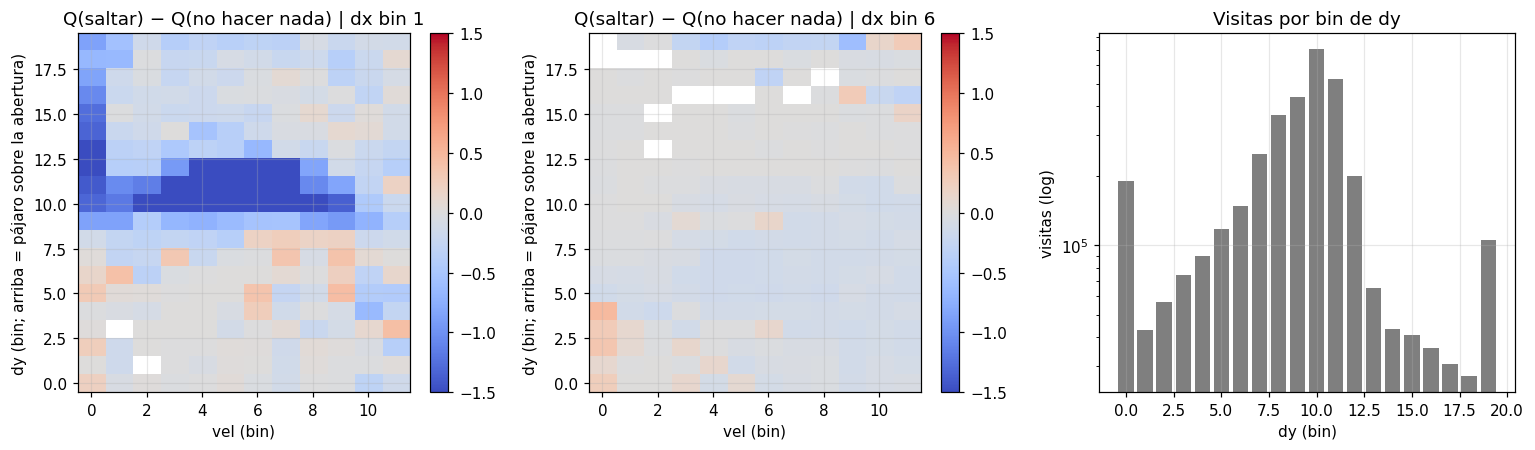

Estados visitados: 3,032 de 3,600 (84.2%)
Estados donde el agente prefiere saltar: 12.4% de los visitados


In [ ]:
# Celda 13 – Interpretabilidad de la Q-Table (RNF-02): ¿en qué estados prefiere saltar el agente?
Q, V = agent.Q, agent.visits
pref = Q[..., 1] - Q[..., 0]                                     # >0: prefiere saltar
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a_, i in zip(ax[:2], [1, 6]):
    m = np.ma.masked_where(V[i] == 0, pref[i])                   # (dy × vel); se ocultan estados no visitados
    im = a_.imshow(m, origin="lower", cmap="coolwarm", vmin=-1.5, vmax=1.5, aspect="auto")
    a_.set(title=f"Q(saltar) − Q(no hacer nada) | dx bin {i}", xlabel="vel (bin)", ylabel="dy (bin; arriba = pájaro sobre la abertura)")
    plt.colorbar(im, ax=a_)
cov = (V.sum(axis=(0, 2)) > 0)
ax[2].bar(range(CONFIG["bins"][1]), V.sum(axis=(0, 2)), color="#7f7f7f"); ax[2].set_yscale("log")
ax[2].set(title="Visitas por bin de dy", xlabel="dy (bin)", ylabel="visitas (log)")
plt.tight_layout(); plt.savefig("fig_06_politica.png", dpi=150); plt.show()
print(f"Estados visitados: {(V>0).sum():,} de {V.size:,} ({(V>0).mean():.1%})")
print(f"Estados donde el agente prefiere saltar: {(pref[V>0] > 0).mean():.1%} de los visitados")

Episodio grabado: 601 fotogramas, puntaje 12


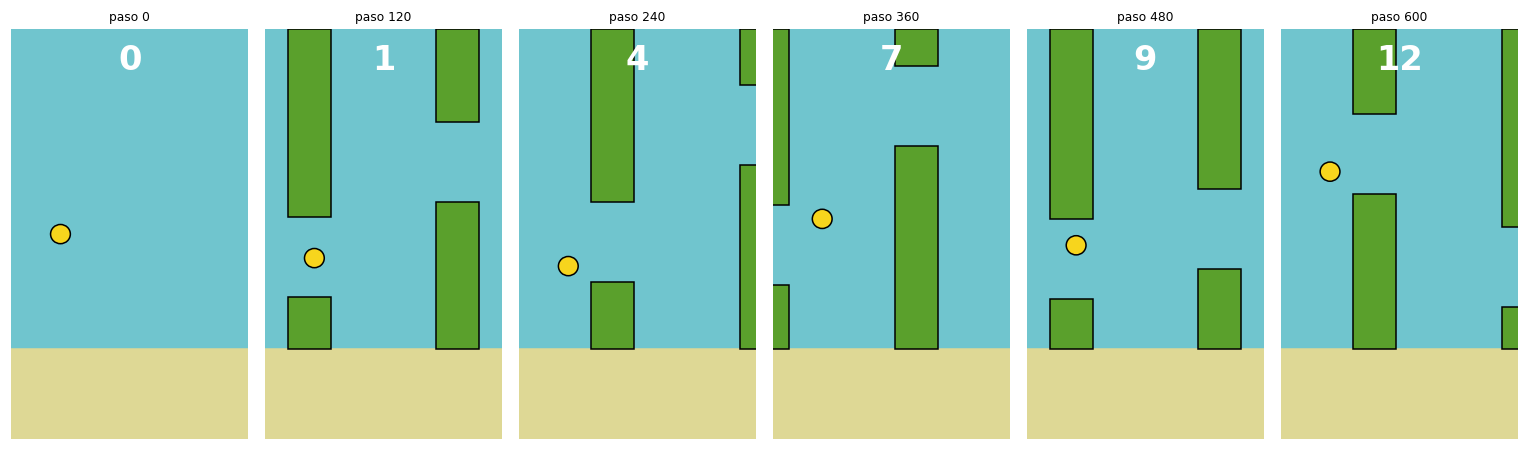

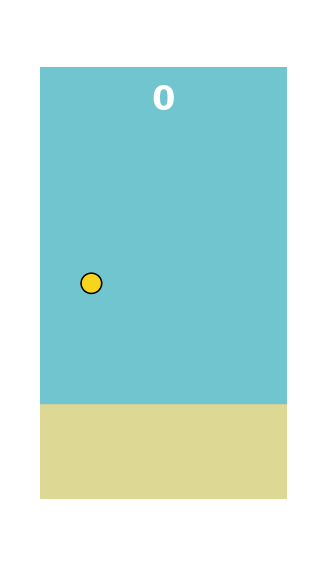

In [ ]:
# Celda 14 – RNF-06: visualización del agente jugando (política greedy)
def draw(ax, s):
    E = FlappyBirdEnv; ax.clear(); ax.set_xlim(0, E.W); ax.set_ylim(E.H, 0); ax.axis("off")
    ax.add_patch(Rectangle((0, 0), E.W, E.GROUND, color="#70c5ce")); ax.add_patch(Rectangle((0, E.GROUND), E.W, E.H - E.GROUND, color="#ded895"))
    for x, cy, _ in s["pipes"]:
        ax.add_patch(Rectangle((x, 0), E.PIPE_W, cy - E.GAP / 2, color="#5aa02c", ec="k"))
        ax.add_patch(Rectangle((x, cy + E.GAP / 2), E.PIPE_W, E.GROUND - cy - E.GAP / 2, color="#5aa02c", ec="k"))
    ax.add_patch(Circle((E.BIRD_X, s["y"]), E.BIRD_R, color="#f7d51d", ec="k", zorder=5))
    ax.text(E.W / 2, 50, str(s["score"]), ha="center", fontsize=22, weight="bold", color="white")

env_v = FlappyBirdEnv(max_steps=600); s = disc.discretize(env_v.reset(TEST_SEED0)); frames = [env_v.snapshot()]
while True:
    obs, r, done, info = env_v.step(agent.select_action(s, greedy=True)); s = disc.discretize(obs); frames.append(env_v.snapshot())
    if done: break
print(f"Episodio grabado: {len(frames)} fotogramas, puntaje {info['score']}")

idx = np.linspace(0, len(frames) - 1, 6).astype(int)             # tira de fotogramas (figura estática)
fig, ax = plt.subplots(1, 6, figsize=(14, 4.2))
for a_, k in zip(ax, idx): draw(a_, frames[k]); a_.set_title(f"paso {k}", fontsize=8)
plt.tight_layout(); plt.savefig("fig_07_fotogramas.png", dpi=150); plt.show()

from matplotlib.animation import FuncAnimation, PillowWriter     # animación GIF
fig, ax = plt.subplots(figsize=(2.9, 5.1))
anim = FuncAnimation(fig, lambda k: draw(ax, frames[k * 2]), frames=len(frames) // 2, interval=40)
anim.save("flappy_agente.gif", writer=PillowWriter(fps=25)); plt.close(fig)
try: display(Image(filename="flappy_agente.gif"))
except Exception: print("GIF guardado: flappy_agente.gif")

In [ ]:
# Celda 15 – RF-07: guardar / cargar la Q-Table y comprobar que reproduce el mismo desempeño
agent2 = QLearningAgent.load("qtable_flappy.pkl")
chk = evaluate(agent2, disc, range(TEST_SEED0, TEST_SEED0 + 20), CONFIG["max_steps_test"])
ref = evaluate(agent,  disc, range(TEST_SEED0, TEST_SEED0 + 20), CONFIG["max_steps_test"])
print("Q-Table idéntica tras cargar:", np.array_equal(agent.Q, agent2.Q), "| mismos puntajes:", (chk.score == ref.score).all())
print("Tamaño del archivo:", os.path.getsize("qtable_flappy.pkl") // 1024, "KB")

Q-Table idéntica tras cargar: True | mismos puntajes: True
Tamaño del archivo: 84 KB


In [ ]:
# Celda 16 – Resumen final de métricas y descarga de resultados
resumen_final = pd.DataFrame({
    "Métrica": ["Episodios de entrenamiento", "Puntaje medio (prueba, ε=0)", "Puntaje máximo (prueba)", "Desviación estándar (prueba)",
                "Tasa de supervivencia (prueba)", "Puntaje medio del agente aleatorio", "Estados visitados"],
    "Valor": [CONFIG["n_train"], round(test.score.mean(), 1), int(test.score.max()), round(test.score.std(), 1),
              f"{1 - test.choque.mean():.1%}", round(base.score.mean(), 2), f"{(V > 0).mean():.1%}"]})
display(resumen_final)
try:                                                              # descarga automática en Colab
    from google.colab import files
    for f in ["qtable_flappy.pkl", "flappy_agente.gif"] + sorted(x for x in os.listdir(".") if x.startswith("fig_")):
        files.download(f)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en el directorio actual.")

,Métrica,Valor
0,Episodios de entrenamiento,10000
1,"Puntaje medio (prueba, ε=0)",98.7
2,Puntaje máximo (prueba),221
3,Desviación estándar (prueba),69.5
4,Tasa de supervivencia (prueba),11.5%
5,Puntaje medio del agente aleatorio,0.0
6,Estados visitados,84.2%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>